# Web Scraping MyAnimeList
Proses pengambilan data 1500 anime teratas dari platform MyAnimeList menggunakan requests dan BeautifulSoup

In [19]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import time
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
def scrape_myanimelist(total_target=1500):
    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36"
    }
    
    anime_data = []
    limit = 0 
    
    print(f"scraping MyAnimeList (Target: {total_target} data | Delay: 5s)...\n")
    
    while len(anime_data) < total_target:
        url = f"https://myanimelist.net/topanime.php?limit={limit}"   
        try:
            res = requests.get(url, headers=headers, timeout=10)
            if res.status_code != 200:
                print(f" [!] Gagal memuat halaman limit={limit}. Status: {res.status_code}")
                break
                
            soup = BeautifulSoup(res.text, 'html.parser')
            rows = soup.find_all('tr', class_='ranking-list')
            
            if not rows:
                print(" [!] Tidak ada elemen anime ditemukan.")
                break
                
            for row in rows:
                if len(anime_data) >= total_target:
                    break
                
                title_elem = row.find('div', class_='detail')
                title = title_elem.find('a').text.strip() if title_elem and title_elem.find('a') else None
                
                score_elem = row.find('td', class_='score')
                score = float(score_elem.text.strip()) if score_elem and score_elem.text.strip() != 'N/A' else None
                
                info_div = row.find('div', class_='information')
                info_text = info_div.text.strip() if info_div else ""
                lines = [line.strip() for line in info_text.split('\n') if line.strip()]
                
                media_type, episodes, year, members = None, None, None, None
                
                if len(lines) >= 1:
                    parts = lines[0].split('(')
                    media_type = parts[0].strip() if len(parts) > 0 else None
                    if len(parts) > 1:
                        episodes = parts[1].replace('eps)', '').replace('ep)', '').strip()
                
                if len(lines) >= 2:
                    year_match = re.search(r'\b(19\d\d|20\d\d)\b', lines[1])
                    year = year_match.group(1) if year_match else None
                        
                if len(lines) >= 3:
                    members_match = re.search(r'([\d,]+)\s*members', lines[2])
                    if members_match:
                        members = int(members_match.group(1).replace(',', ''))
                
                if title:
                    anime_data.append({
                        'Title': title,
                        'Year': year,
                        'Type': media_type,
                        'Episodes': episodes,
                        'Rating': score,
                        'Votes': members
                    })
            
            limit += 50
            time.sleep(3.0)
            
        except Exception as e:
            print(f" [!] Error: {e}")
            break

    df = pd.DataFrame(anime_data)
    df.to_csv('mal_raw_1500.csv', index=False, encoding='utf-8')
    print(f"\n[SUKSES] Berhasil menyimpan {len(df)} baris data ke 'mal_raw_1500.csv'")
    return df

df = scrape_myanimelist(1500)
df.head()

scraping MyAnimeList (Target: 1500 data | Delay: 5s)...


[SUKSES] Berhasil menyimpan 1500 baris data ke 'mal_raw_1500.csv'


,Title,Year,Type,Episodes,Rating,Votes
0,Sousou no Frieren,2023,TV,28,9.25,1513092
1,Fullmetal Alchemist: Brotherhood,2009,TV,64,9.11,3733719
2,Re:Zero kara Hajimeru Isekai Seikatsu 4th Season,2026,TV,19,9.11,326780
3,Steel Ball Run: JoJo no Kimyou na Bouken,2026,ONA,?,9.08,232984
4,Bleach: Sennen Kessen-hen - Kashin-tan,2026,TV,10,9.07,162489


In [31]:
df = pd.read_csv("mal_raw_1500.csv")

print("Dimensi dataset")
print(f"Jumlah Baris: {df.shape[0]} | Jumlah Kolom: {df.shape[1]}\n")

print("tipe data")
df.info()

print("\nMissing Values")
placeholders = ["?", "Unknown", "N/A", "None", "-"]
df_clean = df.replace(placeholders, np.nan)
print(df_clean.isnull().sum())

print("\nDuplicate")
print("Baris duplikat persis:", df.duplicated().sum())
if "Title" in df.columns:
    print("Duplikat berdasarkan Title:", df.duplicated(subset=["Title"]).sum())

df.head()

Dimensi dataset
Jumlah Baris: 1500 | Jumlah Kolom: 6

tipe data
<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Title     1500 non-null   str    
 1   Year      1500 non-null   int64  
 2   Type      1500 non-null   str    
 3   Episodes  1500 non-null   str    
 4   Rating    1500 non-null   float64
 5   Votes     1500 non-null   int64  
dtypes: float64(1), int64(2), str(3)
memory usage: 118.5 KB

Missing Values
Title       0
Year        0
Type        0
Episodes    9
Rating      0
Votes       0
dtype: int64

Duplicate
Baris duplikat persis: 0
Duplikat berdasarkan Title: 0


,Title,Year,Type,Episodes,Rating,Votes
0,Sousou no Frieren,2023,TV,28,9.25,1513092
1,Fullmetal Alchemist: Brotherhood,2009,TV,64,9.11,3733719
2,Re:Zero kara Hajimeru Isekai Seikatsu 4th Season,2026,TV,19,9.11,326780
3,Steel Ball Run: JoJo no Kimyou na Bouken,2026,ONA,?,9.08,232984
4,Bleach: Sennen Kessen-hen - Kashin-tan,2026,TV,10,9.07,162489


In [32]:
df['Episodes'] = pd.to_numeric(df['Episodes'], errors='coerce')
df['Year'] = pd.to_numeric(df['Year'], errors='coerce')

df['Episodes'] = df['Episodes'].fillna(df['Episodes'].median())
df['Year'] = df['Year'].fillna(df['Year'].median())
df['Rating'] = df['Rating'].fillna(df['Rating'].mean())
df['Votes'] = df['Votes'].fillna(df['Votes'].median())

df['Episodes'] = df['Episodes'].astype(int)
df['Year'] = df['Year'].astype(int)
df['Votes'] = df['Votes'].astype(int)

print("Jumlah missing values setelah clean:")
print(df.isnull().sum())

df.to_csv("mal_clean_1500.csv", index=False)
print("\nData bersih disimpan ke 'mal_clean_1500.csv'!")

Jumlah missing values setelah clean:
Title       0
Year        0
Type        0
Episodes    0
Rating      0
Votes       0
dtype: int64

Data bersih disimpan ke 'mal_clean_1500.csv'!


# Exploratory Data Analysis (EDA)


Menganalisis persebaran data numerik seperti mean, median, standar deviasi, min, dan max.

In [23]:
num_cols = ['Year', 'Episodes', 'Rating', 'Votes']
stat_summary = df[num_cols].describe().T
stat_summary['median'] = df[num_cols].median()
stat_summary['std_dev'] = df[num_cols].std()

print("Statistik deskriptif fitur numerik")
display(stat_summary[['mean', 'median', 'std_dev', 'min', '50%', 'max']])

print(f"\nModus Format Anime (Type) : {df['Type'].mode()[0]}")

Statistik deskriptif fitur numerik


,mean,median,std_dev,min,50%,max
Year,2014.286000,2016.0,9.881766,1970.00,2016.0,2026.00
Episodes,18.874000,12.0,57.140833,1.00,12.0,1787.00
Rating,8.073840,8.0,0.309702,7.69,8.0,9.25
Votes,380140.310667,161959.5,560980.127378,860.00,161959.5,4424215.00



Modus Format Anime (Type) : TV


Mengecek pencilan nilai (*outliers*) pada fitur Votes dan Rating

In [24]:
def detect_outliers_iqr(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - (1.5 * iqr)
    upper_bound = q3 + (1.5 * iqr)
    
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    print(f"Fitur [{column}] -> Q1: {q1:.2f}, Q3: {q3:.2f}, IQR: {iqr:.2f}")
    print(f"  Batas Bawah: {lower_bound:.2f} | Batas Atas: {upper_bound:.2f}")
    print(f"  Jumlah Outlier: {len(outliers)} baris ({len(outliers)/len(data)*100:.2f}%)\n")
    return outliers

print("deteksi outliers")
outliers_votes = detect_outliers_iqr(df, 'Votes')
outliers_rating = detect_outliers_iqr(df, 'Rating')

deteksi outliers
Fitur [Votes] -> Q1: 53410.50, Q3: 444603.25, IQR: 391192.75
  Batas Bawah: -533378.62 | Batas Atas: 1031392.38
  Jumlah Outlier: 148 baris (9.87%)

Fitur [Rating] -> Q1: 7.82, Q3: 8.26, IQR: 0.44
  Batas Bawah: 7.16 | Batas Atas: 8.92
  Jumlah Outlier: 23 baris (1.53%)



menampilkan visualisasi untuk mengecek skor, jumlah anime berdasarkan format, dan sebaran tahunnya

C:\Users\Nazwar\AppData\Local\Temp\ipykernel_14916\4217728109.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Type', ax=axes[1], palette='viridis', order=df['Type'].value_counts().index)


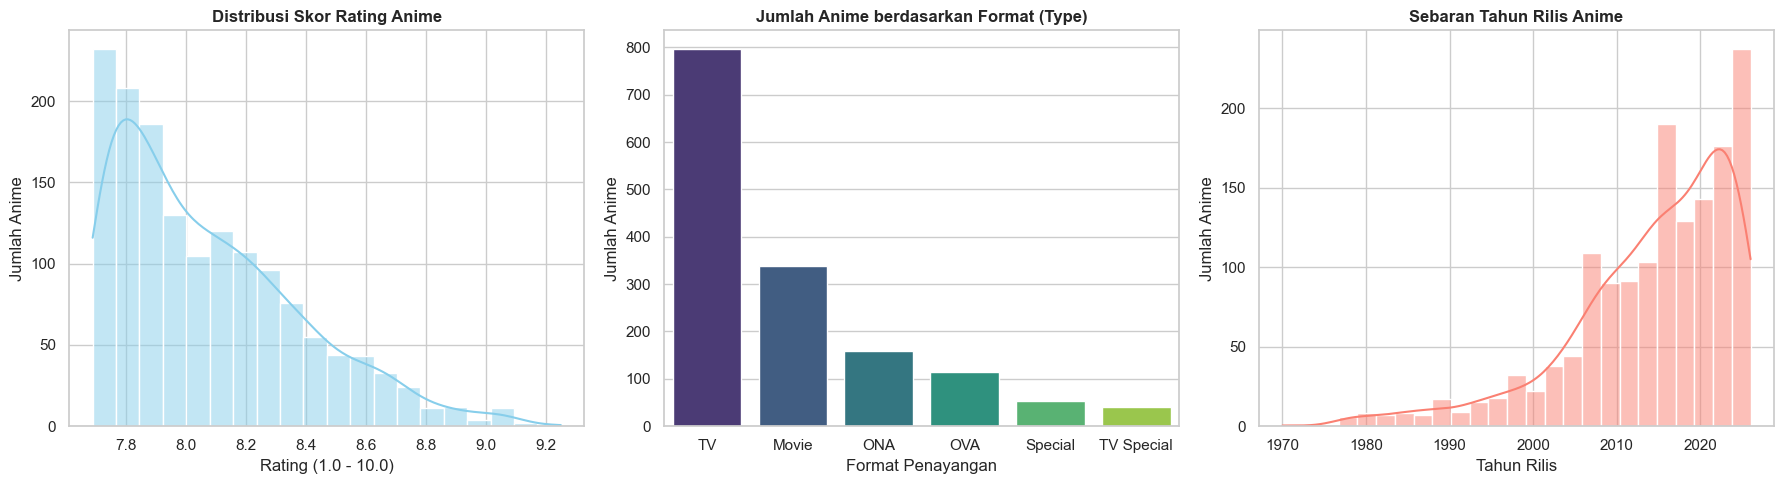

In [25]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['Rating'], kde=True, ax=axes[0], color='skyblue', bins=20)
axes[0].set_title('Distribusi Skor Rating Anime', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Rating (1.0 - 10.0)')
axes[0].set_ylabel('Jumlah Anime')

sns.countplot(data=df, x='Type', ax=axes[1], palette='viridis', order=df['Type'].value_counts().index)
axes[1].set_title('Jumlah Anime berdasarkan Format (Type)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Format Penayangan')
axes[1].set_ylabel('Jumlah Anime')

sns.histplot(df['Year'], kde=True, ax=axes[2], color='salmon', bins=25)
axes[2].set_title('Sebaran Tahun Rilis Anime', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Tahun Rilis')
axes[2].set_ylabel('Jumlah Anime')

plt.tight_layout()
plt.show()

Distribusi Rating: Kebanyakan anime "numpuk" di skor 7.8 – 8.0. Dapet nilai di atas 8.5 itu udah lumayan langka, dan yang bisa tembus rating 9.0+ beneran cuma segelintir anime masterpiece.

Format Penayangan: Serial TV tetep jadi yang paling mendominasi pasar, disusul sama Movie layar lebar. Format lain kayak ONA, OVA, atau Special cuma jadi pelengkap aja.

Tahun Rilis: Industri anime makin ke sini makin meledak. Didominasi banget sama rilisan era 2010-an ke atas (puncaknya di era 2020-an), sementara anime klasik era 80–90an yang bertahan di daftar ini cuma dikit.

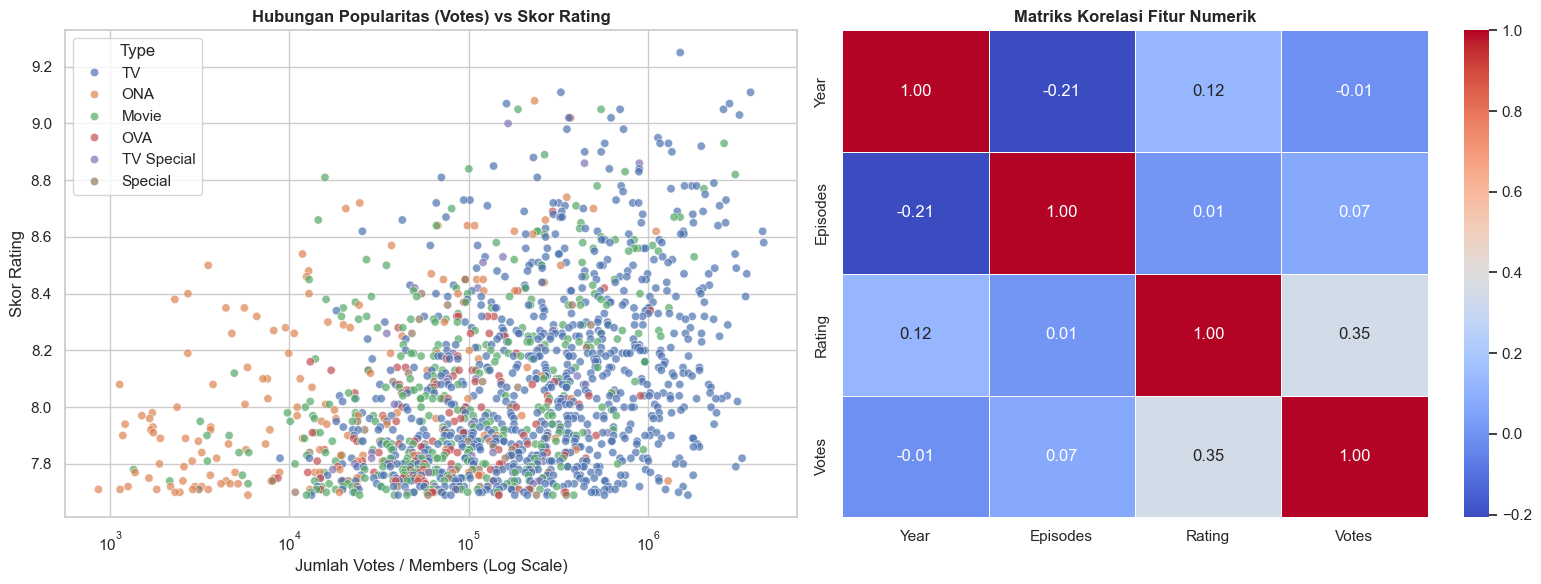

C:\Users\Nazwar\AppData\Local\Temp\ipykernel_14916\2804716515.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


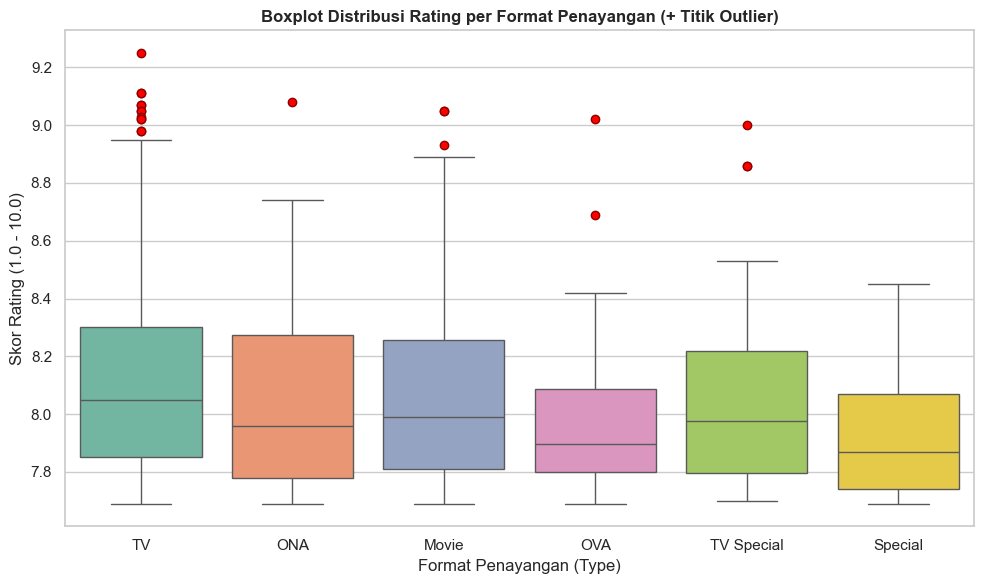

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=df, x='Votes', y='Rating', hue='Type', alpha=0.7, ax=axes[0])
axes[0].set_title('Hubungan Popularitas (Votes) vs Skor Rating', fontsize=12, fontweight='bold')
axes[0].set_xscale('log') # Skala logaritmik karenaVotes sangat skewed
axes[0].set_xlabel('Jumlah Votes / Members (Log Scale)')
axes[0].set_ylabel('Skor Rating')

corr = df[['Year', 'Episodes', 'Rating', 'Votes']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, ax=axes[1])
axes[1].set_title('Matriks Korelasi Fitur Numerik', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df, x='Type', y='Rating', palette='Set2',
    flierprops={'markerfacecolor': 'red', 'markeredgecolor': 'darkred', 'markersize': 6}
)

plt.title('Boxplot Distribusi Rating per Format Penayangan (+ Titik Outlier)', fontsize=12, fontweight='bold')
plt.xlabel('Format Penayangan (Type)')
plt.ylabel('Skor Rating (1.0 - 10.0)')
plt.tight_layout()
plt.show()

### Hubungan Popularitas dan Korelasi

- Makin Ramai, Rating Cenderung Naik
  Anime dengan jumlah votes melimpah hampir selalu punya skor di atas 8.0. Jarang sekali ada anime populer yang mendapat nilai jelek dari penonton.

- Anime Modern Makin Pendek
  Korelasi negatif antara tahun dan episode menunjukkan tren bahwa anime zaman sekarang lebih menyukai format musiman pendek antara 12 hingga 24 episode dibanding anime terdahulu yang episodenya mencapai ratusan.

- Jumlah Episode Tidak Mempengaruhi Kualitas
  Mau episodenya hanya 12 atau sampai ratusan, jumlah episode tidak menjamin rating nya akan bagus atau jelek.

### Distribusi Rating per Format Penayangan

- Format TV Paling Konsisten
  Memiliki nilai tengah rating paling tinggi dan stabil, serta paling banyak menyumbang anime berkualitas tinggi dengan rating di atas 9.0.

- Movie Beda Tipis
  Kualitas rata-rata film layar lebar tergolong mirip dengan serial TV, hanya saja sebaran nilainya dari yang standar sampai yang bagus sedikit lebih lebar.

- OVA dan TV Special Punya Kuda Hitam
  Secara rata-rata rating nya memang lebih rendah sekitar 7.8 hingga 7.9, tetapi ada beberapa judul spesifik yang memiliki daya tarik tinggi hingga rating nya melesat menembus angka 9.0.

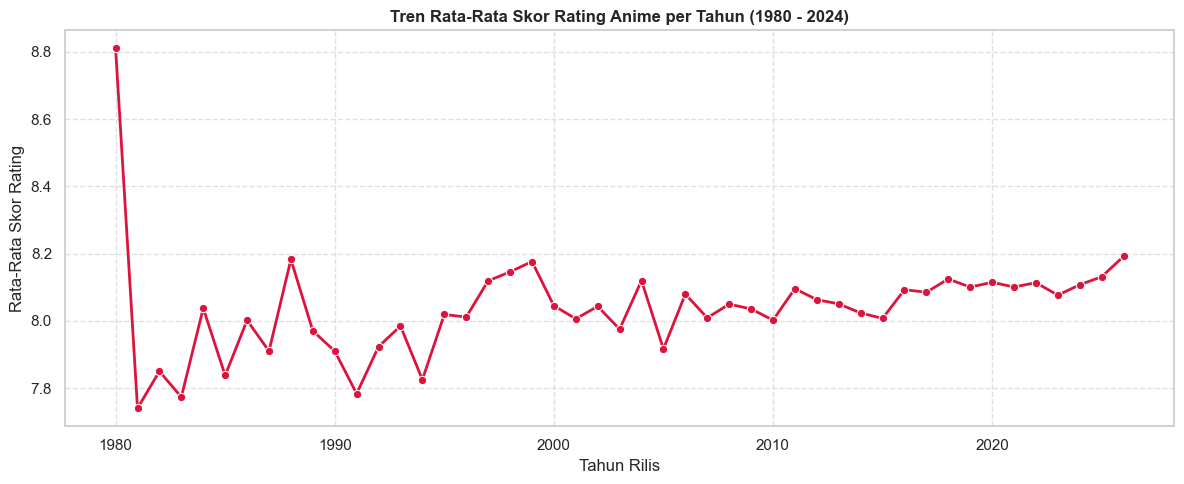

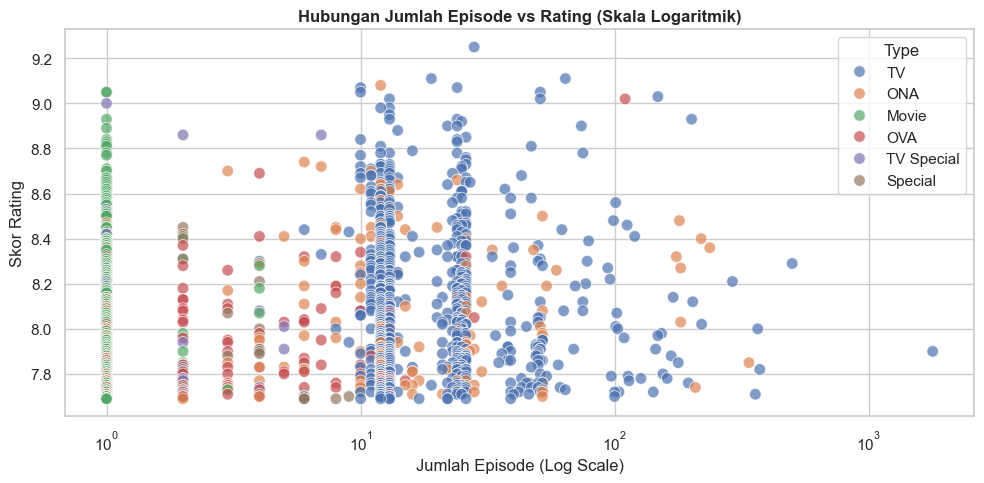

C:\Users\Nazwar\AppData\Local\Temp\ipykernel_14916\3584244555.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_votes, y='Title', x='Votes', ax=axes[0], palette='Blues_r')
C:\Users\Nazwar\AppData\Local\Temp\ipykernel_14916\3584244555.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_rating, y='Title', x='Rating', ax=axes[1], palette='Greens_r')


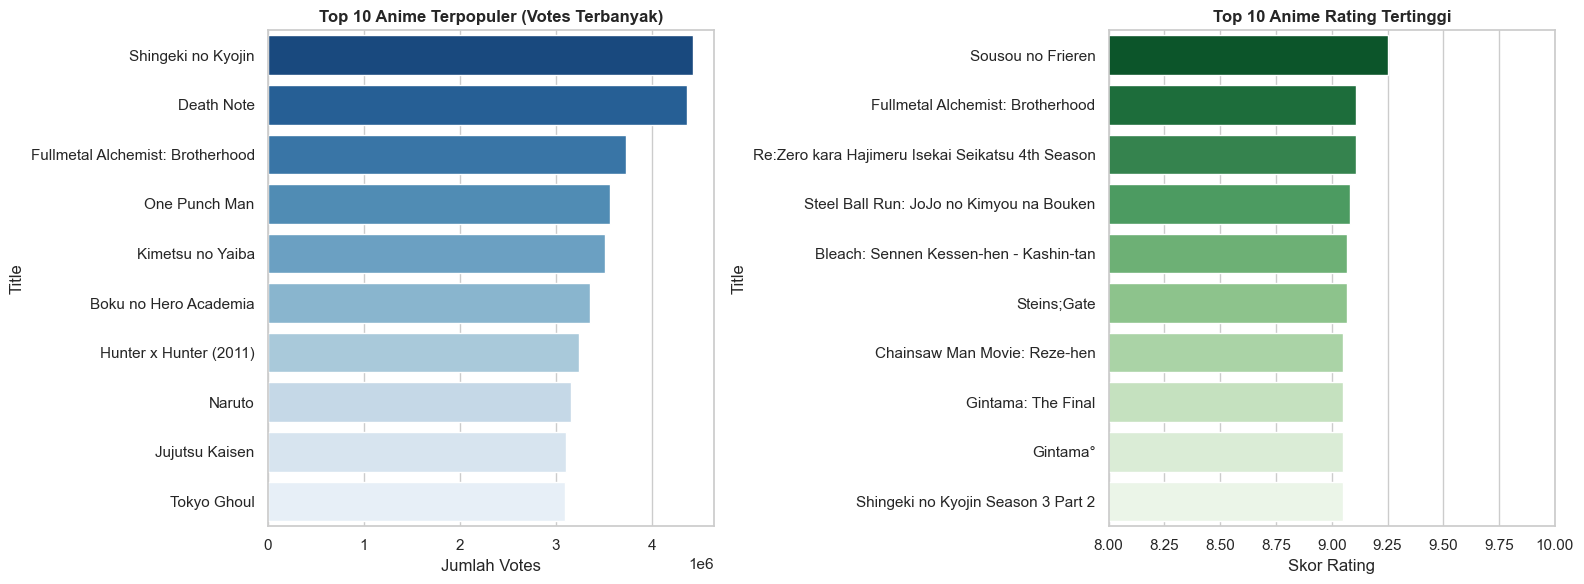

In [27]:
df_yearly = df[df['Year'] >= 1980].groupby('Year')['Rating'].mean().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=df_yearly, x='Year', y='Rating', marker='o', color='crimson', linewidth=2)

plt.title('Tren Rata-Rata Skor Rating Anime per Tahun (1980 - 2024)', fontsize=12, fontweight='bold')
plt.xlabel('Tahun Rilis')
plt.ylabel('Rata-Rata Skor Rating')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='Episodes', y='Rating', hue='Type', alpha=0.7, s=70)

plt.xscale('log')  # Menggunakan skala logaritmik karena episode terdistribusi luas (1 hingga 1000+)
plt.title('Hubungan Jumlah Episode vs Rating (Skala Logaritmik)', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Episode (Log Scale)')
plt.ylabel('Skor Rating')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_votes = df.nlargest(10, 'Votes')
sns.barplot(data=top_votes, y='Title', x='Votes', ax=axes[0], palette='Blues_r')
axes[0].set_title('Top 10 Anime Terpopuler (Votes Terbanyak)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jumlah Votes')

top_rating = df.nlargest(10, 'Rating')
sns.barplot(data=top_rating, y='Title', x='Rating', ax=axes[1], palette='Greens_r')
axes[1].set_title('Top 10 Anime Rating Tertinggi', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Skor Rating')
axes[1].set_xlim(8.0, 10.0)

plt.tight_layout()
plt.show()

### Tren Rata-Rata Rating per Tahun

- Lonjakan Angka pada Anime Klasik
  Rata-rata rating sempat melonjak tinggi di tahun 1980-an. Ini terjadi karena anime lama yang mampu bertahan di jajaran top 1500 hanyalah judul-judul legendaris yang memang dinilai sangat tinggi oleh penonton.

- Tren Modern Makin Stabil dan Meningkat
  Mulai dari tahun 2010 hingga 2024, grafik menunjukkan kenaikan yang konsisten dari angka 8.0 menuju 8.2. Hal ini menandakan standar kualitas produksi dan penerimaan anime era modern makin membaik secara merata.

### Hubungan Jumlah Episode dan Rating

- Pemusatan di Format Musiman
  Sebagian besar titik menumpuk di kisaran 10 hingga 24 episode. Ini menunjukkan bahwa mayoritas anime populer menggunakan format musiman pendek yang didominasi oleh serial TV dan ONA.

- Episode Panjang Tidak Mengunci Rating
  Anime dengan jumlah episode sangat panjang dari 100 hingga di atas 1000 episode menyebar dari rating 7.7 hingga 9.0. Jumlah episode yang banyak tidak membatasi anime untuk mendapat skor tinggi selama kualitas ceritanya terjaga.

- Format Satu Episode Variatif
  Pada posisi 1 episode yang didominasi Movie dan OVA, sebaran rating-nya cukup lebar dari 7.7 hingga mendekati 9.0.

  ### Top 10 Anime Terpopuler dan Rating Tertinggi

- 
  Shingeki no Kyojin dan Death Note mendominasi posisi puncak dengan jumlah votes menembus angka lebih dari 4 juta. Daftar terpopuler ini didominasi oleh judul genre aksi utama yang menjadi gerbang masuk bagi mayoritas penonton anime.

- Kualitas Tertinggi Didominasi Sekuel
  Sousou no Frieren memimpin di posisi pertama dengan rating tertinggi melampaui angka 9.2. Sebagian besar isi daftar rating tertinggi didominasi oleh musim lanjutan atau sekuel seperti Re:Zero Season 4, Bleach, Gintama, dan Attack on Titan Season 3 Part 2. Hal ini terjadi karena penonton musim lanjutan umumnya adalah penggemar setia yang konsisten memberikan nilai tinggi.

- Keseimbangan Popularitas dan Kualitas
  Fullmetal Alchemist: Brotherhood dan Shingeki no Kyojin menjadi judul langka yang berhasil menembus jajaran teratas pada kedua kategori sekaligus. Ini membuktikan bahwa keduanya tidak hanya populer secara masif, tetapi juga diakui memiliki kualitas cerita yang sangat solid oleh komunitas.